# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN CUSTOMER CHURN

## 1. Giới thiệu

Notebook này thực hiện xây dựng, đánh giá và tối ưu các mô hình Machine Learning
nhằm dự đoán khả năng khách hàng rời bỏ dịch vụ (**Customer Churn**).

Ba thuật toán được sử dụng gồm:

- **K-Nearest Neighbors (KNN)**
- **Decision Tree (DT)**
- **Naive Bayes (NB)**

### Mục tiêu

- Xây dựng mô hình baseline cho từng thuật toán.
- Đánh giá hiệu quả mô hình bằng các chỉ số phù hợp.
- Tối ưu siêu tham số nhằm cải thiện hiệu suất dự đoán.
- So sánh mô hình trước và sau khi tối ưu.
- So sánh ba thuật toán và lựa chọn mô hình phù hợp cho bài toán Customer Churn.

### Quy trình thực hiện

**Dữ liệu đã tiền xử lý → Baseline → Đánh giá → Tối ưu → Đánh giá lại → So sánh mô hình**

## 2. Khởi tạo môi trường

Import các thư viện cần thiết cho quá trình xây dựng, đánh giá,
tối ưu và trực quan hóa các mô hình Machine Learning.

In [225]:
# Xử lý dữ liệu
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Trực quan hóa
import matplotlib.pyplot as plt

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model selection
from sklearn.model_selection import GridSearchCV

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

## 3. Chuẩn bị dữ liệu cho Modeling

Dữ liệu sử dụng trong notebook này được kế thừa từ bước
Data Understanding & Preprocessing của nhóm.

Ở bước trước, dữ liệu đã được:

- Làm sạch và xử lý missing values.
- Chia thành tập train/test bằng stratified sampling.
- Chuẩn hóa các biến số.
- One-Hot Encoding các biến phân loại.
- Fit preprocessing trên tập train và transform tập test.

Notebook này sử dụng trực tiếp các tập dữ liệu đã tiền xử lý
để đảm bảo toàn bộ các mô hình được huấn luyện và đánh giá
trên cùng một dữ liệu.

In [226]:
DATA_DIR = Path("../data")

X_train = np.load(DATA_DIR / "X_train_processed.npy")
X_test = np.load(DATA_DIR / "X_test_processed.npy")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

feature_names = joblib.load(
    DATA_DIR / "feature_names.pkl"
)

class_weight = joblib.load(
    DATA_DIR / "class_weight.pkl"
)

In [227]:
print(f"Kích thước dữ liệu")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

Kích thước dữ liệu
X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634,)
y_test : (1409,)
Number of features: 40


### Nhận xét

Dữ liệu sau tiền xử lý gồm **40 đặc trưng** và được chia thành
**5.634 mẫu huấn luyện** và **1.409 mẫu kiểm thử**.

Phân bố nhãn cho thấy số khách hàng không Churn lớn hơn số khách hàng Churn.
Do đó, ngoài Accuracy, các chỉ số **Precision, Recall và F1-score**
cần được xem xét khi đánh giá mô hình.

In [228]:
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == len(feature_names)

print("Shape alignment OK")

Shape alignment OK


In [229]:
# y_train = y_train.squeeze()
# y_test = y_test.squeeze()

# print("y_train shape:", y_train.shape)
# print("y_test shape :", y_test.shape)

In [230]:
print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

Train labels: [0 1]
Test labels : [0 1]


In [231]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [232]:
print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


## 4. Các hàm đánh giá dùng chung

Để đảm bảo các mô hình được đánh giá theo cùng một quy trình,
các hàm đánh giá được định nghĩa một lần và tái sử dụng cho KNN,
Decision Tree và Naive Bayes.

Các chỉ số chính gồm:

- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ dữ liệu.
- **Precision:** mức độ chính xác của các dự đoán Churn.
- **Recall:** khả năng phát hiện khách hàng thực sự Churn.
- **F1-score:** cân bằng giữa Precision và Recall.
- **Confusion Matrix:** thể hiện số lượng TN, FP, FN và TP.

In [233]:
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    # Tính các metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    # In metrics
    print(f"===== {model_name} =====")
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1-score : {results['F1-score']:.4f}")
    print(f"ROC-AUC  : {results['ROC-AUC']:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return results

##  5. K-Nearest Neighbors

### 5.1 Tổng quan

KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới
      ↓
① Tính khoảng cách với khách trong train
      ↓
② Tìm K người gần nhất
      ↓
③ Xem họ thuộc class 0 hay 1
      ↓
④ Majority vote
      ↓
Dự đoán Churn / No Churn


### 5.2 KNN Baseline

In [234]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train, y_train); # train

In [235]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

Đánh giá KNN baseline 
| Metric    | Câu hỏi nó trả lời                                          |
| --------- | ----------------------------------------------------------- |
| Accuracy  | Tổng thể model đoán đúng bao nhiêu %?                       |
| Precision | Những người model báo churn, bao nhiêu người thực sự churn? |
| Recall    | Những người thực sự churn, model bắt được bao nhiêu?        |
| F1-score  | Cân bằng Precision và Recall                                |
| ROC-AUC   | Model phân biệt churn và non-churn tốt đến đâu?             |

0.5  → gần như random
0.6  → yếu
0.7  → khá
0.8  → tốt
0.9+ → rất tốt
1.0  → hoàn hảo

## 5.3 Đánh giá Baseline

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332
ROC-AUC  : 0.7820

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


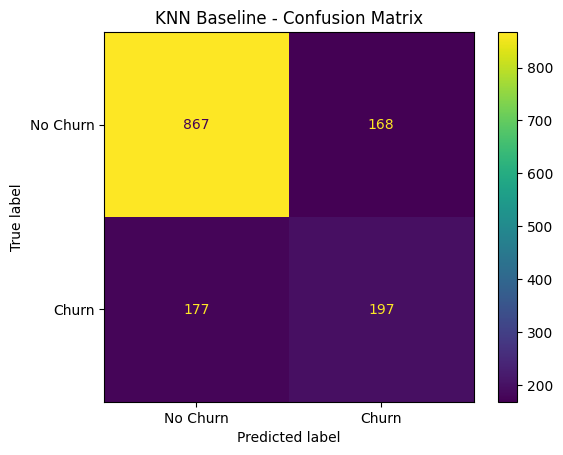

In [236]:
knn_baseline_result = evaluate_model( # danh gia mo hinh 
  y_test, 
  y_predict_knn_baseline, 
  y_proba_km, 
"KNN Baseline") 

1. trong 100 khách -> model dự đoán trúnga 76 khách
2. model cảnh báo 100 khách -> 54 churn thực sự
3. 100 người churn -> model phát hiện được 53 người
4. 
5. yếu

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

---

>  *Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ*

## 5.4 Tối ưu siêu tham số KNN

Hiệu suất của KNN phụ thuộc nhiều vào số lượng láng giềng `k`
(`n_neighbors`). Giá trị `k` quá nhỏ có thể khiến mô hình nhạy với nhiễu,
trong khi giá trị `k` quá lớn có thể làm giảm khả năng phân biệt giữa các lớp.

Trong phần này, **GridSearchCV** được sử dụng để thử nghiệm nhiều giá trị
`n_neighbors` và lựa chọn giá trị tốt nhất thông qua **5-fold cross-validation**.

Do dữ liệu Customer Churn có sự mất cân bằng giữa hai lớp,
**F1-score** được sử dụng làm tiêu chí tối ưu nhằm cân bằng giữa
Precision và Recall.

| 5W1H       | Giải thích                                                                                                                                                                           |
| ---------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **What?**  | **KNN Tuned** là mô hình K-Nearest Neighbors sau khi tối ưu siêu tham số. Trong bài của bạn, tham số được tối ưu là `n_neighbors`, và kết quả tốt nhất là **k = 21**.                |
| **Why?**   | KNN Baseline sử dụng mặc định `k = 5`, nhưng giá trị mặc định chưa chắc phù hợp với dữ liệu Customer Churn. Tuning nhằm tìm `k` giúp mô hình nhận diện Churn tốt hơn.                |
| **When?**  | Thực hiện sau khi đã xây dựng và đánh giá KNN Baseline. Chỉ đánh giá trên `X_test` sau khi quá trình lựa chọn `k` bằng training data hoàn tất.                                       |
| **Where?** | Trong notebook: **5.4 Tối ưu siêu tham số KNN → 5.5 Đánh giá KNN Tuned**.                                                                                                            |
| **Who?**   | `GridSearchCV` thử các giá trị `k`; `KNeighborsClassifier` thực hiện classification; dữ liệu train dùng để tuning và test dùng để đánh giá cuối cùng.                                |
| **How?**   | Thử nhiều `k` → 5-fold CV → tính F1 cho từng cấu hình → chọn `k` tốt nhất → train best model → predict test → đánh giá Accuracy, Precision, Recall, F1, ROC-AUC và Confusion Matrix. |


- K = 5 ? 
- K quá nhỏ -> nhạy với noise -> overfiting 
- K quá lớn -> quá rộng -> mất pattern toàn cục
---
*cần tìm k phù hợp*
--- 
X_train -> Cross-validation -> thử K khác nhau -> chọn best K -> train best model -> X_test <- chỉ đánh giá cuối cùng


In [237]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25]
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train);


In [238]:
print("Best parameters:", grid_knn.best_params_)
print(f"Best CV F1-score: {grid_knn.best_score_:.4f}")

Best parameters: {'n_neighbors': 21}
Best CV F1-score: 0.6047


In [239]:
best_knn = grid_knn.best_estimator_

y_predict_knn_tuned = best_knn.predict(X_test)
y_prob_knn_tuned = best_knn.predict_proba(X_test)[:, 1]

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884
ROC-AUC  : 0.8239

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


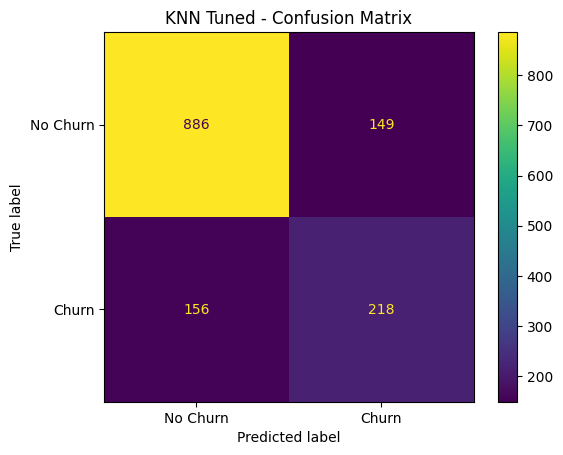

In [240]:
knn_tuned_result = evaluate_model( # danh gia mo hinh 
    y_test,
    y_predict_knn_tuned,
    y_prob_knn_tuned,
    "KNN Tuned"
)

### Nhận xét

Sau khi tối ưu siêu tham số với `n_neighbors = 21`, mô hình KNN đạt:

- **Accuracy = 78.35%**: mô hình dự đoán đúng khoảng 78% khách hàng.
- **Precision = 59.40%**: trong số khách hàng được dự đoán là Churn,
  khoảng 59% thực sự rời bỏ dịch vụ.
- **Recall = 58.29%**: mô hình phát hiện được khoảng 58% khách hàng
  thực sự Churn.
- **F1-score = 58.84%**: cho thấy sự cân bằng giữa Precision và Recall
  đã được cải thiện.
- **ROC-AUC = 82.39%**: mô hình có khả năng phân biệt tương đối tốt
  giữa khách hàng Churn và No Churn.

Từ Confusion Matrix:

- **TN = 886**: dự đoán đúng khách hàng không Churn.
- **FP = 149**: khách hàng không Churn nhưng bị dự đoán là Churn.
- **FN = 156**: khách hàng thực sự Churn nhưng mô hình không phát hiện được.
- **TP = 218**: khách hàng Churn được mô hình phát hiện chính xác.

Mặc dù vẫn còn 156 trường hợp Churn bị bỏ sót, kết quả cho thấy mô hình
KNN sau tối ưu có khả năng nhận diện khách hàng Churn tốt hơn so với
mô hình baseline.

## 5.6 Baseline vs Tuned

In [246]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

comparison_table = pd.DataFrame({
    "Baseline": [
        knn_baseline_result[m] for m in metrics
    ],
    "Tuned": [
        knn_tuned_result[m] for m in metrics
    ]
}, index=metrics)

comparison_table["Improvement"] = (
    comparison_table["Tuned"] - comparison_table["Baseline"]
)

comparison_table.round(4)


,Baseline,Tuned,Improvement
Accuracy,0.7551,0.7835,0.0284
Precision,0.5397,0.5940,0.0543
Recall,0.5267,0.5829,0.0561
F1-score,0.5332,0.5884,0.0552
ROC-AUC,0.7820,0.8239,0.0419


In [252]:
cm_baseline = confusion_matrix(
    y_test,
    y_predict_knn_baseline
)

cm_tuned = confusion_matrix(
    y_test,
    y_predict_knn_tuned
)

tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()

cm_comparison = pd.DataFrame({
    "Baseline": [tn_b, fp_b, fn_b, tp_b],
    "Tuned": [tn_t, fp_t, fn_t, tp_t]
}, index=["TN", "FP", "FN", "TP"])

cm_comparison["Change"] = (
    cm_comparison["Tuned"] - cm_comparison["Baseline"]
)

cm_comparison

,Baseline,Tuned,Change
TN,867,886,19
FP,168,149,-19
FN,177,156,-21
TP,197,218,21


### Kết luận so sánh

KNN Tuned (`k = 21`) cho kết quả tốt hơn KNN Baseline (`k = 5`)
trên toàn bộ các chỉ số đánh giá.

- Accuracy tăng từ **75.51% lên 78.35%**.
- Precision tăng từ **53.97% lên 59.40%**.
- Recall tăng từ **52.67% lên 58.29%**.
- F1-score tăng từ **53.32% lên 58.84%**.
- ROC-AUC tăng từ **78.20% lên 82.39%**.

Đối với lớp Churn, số True Positive tăng từ **197 lên 218**,
trong khi False Negative giảm từ **177 xuống 156**. Như vậy,
mô hình sau tối ưu phát hiện thêm 21 khách hàng Churn và giảm
21 trường hợp Churn bị bỏ sót trên tập test.

Kết quả cho thấy việc tối ưu `n_neighbors` đã cải thiện khả năng
dự đoán của KNN. Vì vậy, KNN Tuned với `k = 21` được chọn làm
phiên bản KNN cuối cùng để so sánh với Decision Tree và Naive Bayes.